
# Laboratorium 2: Baseline i kasyfikator



W poprzednim laboratorium zaczęliśmy od danych. Dzisiaj budujemy pierwszy pełny eksperyment z zakresu uczenia maszynowego.

Nasza ścieżka:

`dane → baseline → TF-IDF → klasyfikator → metryki → analiza błędów → decyzja`

Interesuje nas:

- jakość,
- stabilność,
- szybkość,
- koszt,
- interpretowalność,
- rodzaj popełnianych błędów.

> **Pytanie badawcze na dziś:** jak mocny jest prosty model tekstowy i kiedy naprawdę potrzebujemy transformera albo LLM-a?

## Po tych zajęciach student potrafi:

- zbudować klasyfikator;
- reprezentować tekst przez TF-IDF;
- wytrenować `LogisticRegression` i `LinearSVC`;
- poprawnie używać `accuracy`, `macro-F1`, `precision`, `recall`;
- analizować confusion matrix;
- porównywać modele eksperymentalnie;
- sprawdzać wpływ długości tekstu na wynik;
- analizować najbardziej pewne błędne predykcje;
- interpretować cechy modelu liniowego;
- przeprowadzić mini „NLP Arena”.

### Zasada na dziś

> **Nowy, większy model musi pokonać mocny baseline. Inaczej nie wiemy, czy naprawdę coś zyskaliśmy.**


## Dane

Laboratorium zakłada, że po wykonaniu laboratorium 1 mają Państwo:

```text
artifacts/polemo2_clean.parquet
artifacts/splits.json
```

Jeśli plików nie ma, proszę wrócić do Lab 1. Nie pobieramy danych ponownie, bo wtedy tracimy czyszczenie, manifest i sumy kontrolne.
Pracujemy na oryginalnym podziale zbioru.


## Setup

In [135]:
!pip install pandas numpy matplotlib scikit-learn pyarrow joblib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [136]:

from pathlib import Path
import json
import time
import os
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)
from sklearn.model_selection import ParameterGrid
import joblib

RANDOM_STATE = 42
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 50)


In [137]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

In [138]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
MANIFEST_PATH = ARTIFACTS / "splits.json"

# TODO: wczytać dane z Lab 1 i utworzyć train_df, val_df, test_df.
# Proszę sprawdzić:
#  - czy suma SHA-256 pliku parquet zgadza się z wartością w splits.json,
#  - czy etykiety to dokładnie: plus / minus / zero / amb,
#  - czy rozmiary splitów zgadzają się z split_sizes_clean z manifestu.
# Jeśli pliku nie ma, proszę wrócić do Lab 1 (nie pobieramy danych "po cichu").

# MIEJSCE NA KOD

import hashlib

if not DATA_PATH.exists() or not MANIFEST_PATH.exists():
    raise FileNotFoundError("Brak artefaktów z Lab 1")

manifest_lab1 = json.loads(MANIFEST_PATH.read_text())

checksum = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if checksum != manifest_lab1["parquet_sha256"]:
    raise ValueError("SHA-256 pliku parquet nie zgadza się z wartością w splits.json")

full_df = pd.read_parquet(DATA_PATH)
CLASSES = ["plus", "minus", "zero", "amb"]

labels_present = set(full_df["target"].unique())
assert labels_present == set(CLASSES), f"Nieoczekiwany zbiór etykiet: {labels_present}"

full_df["n_words"] = full_df["text"].str.count(r"\w+")

train_df = full_df.query("split == 'train'").reset_index(drop=True)
val_df = full_df.query("split == 'validation'").reset_index(drop=True)
test_df = full_df.query("split == 'test'").reset_index(drop=True)

measured_sizes = {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}
assert measured_sizes == manifest_lab1["split_sizes_clean"], (measured_sizes, manifest_lab1["split_sizes_clean"])

print("Weryfikacja artefaktów z Lab 1 OK")
print("  SHA-256 parquet:", checksum[:16], "...")
print("  rozmiary splitów:", measured_sizes)
print("  klasy:", sorted(labels_present))


Weryfikacja artefaktów z Lab 1 OK
  SHA-256 parquet: ddb4a0a3dc578f27 ...
  rozmiary splitów: {'train': 5783, 'validation': 723, 'test': 722}
  klasy: ['amb', 'minus', 'plus', 'zero']


In [139]:
full_df.head()

,text,target,split,text_norm,is_duplicate_in_split,n_words
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...",plus,train,"super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą staruszką , i twierdz...",False,121
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,minus,train,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,False,97
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...",amb,train,"lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora nie mam zastrzeżeń ...",False,48
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",zero,train,""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie trzeba wychodzić z dom...",False,158
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...",plus,train,"pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikatna , bardzo miła , c...",False,103



# Zadanie 1: Zamrożenie protokołu eksperymentalnego

Zanim wytrenują Państwo model, proszę zdefiniować zbiory:

- **train**: do uczenia,
- **validation**: do wyboru wariantu,
- **test**: testowany dopiero na końcu,
- główną metrykę,
- metryki pomocnicze.

### Dla tego laboratorium

Główna metryka: `macro-F1`

Dlaczego nie samo accuracy?

Bo `macro-F1` liczy F1 osobno dla każdej klasy, a potem uśrednia je z równą wagą. Słaba jakość na małej klasie nie „schowa się” za dużą klasą.

### Hipoteza badawcza

Przed uruchomieniem modeli proszę wpisać hipotezę:

> Który model wygra: prosty baseline, Logistic Regression czy Linear SVM? Dlaczego?


>Hipoteza badawcza: Spodziewam się, ze modele liniowe pokonają baseline większościowy. Między nimi spodziewam się zbliżonych wyników. Modele liniowe powinny uczyć się na danych, więc będą mieć lepsze wyniki niz zgadywanie.

In [140]:
# MIEJSCE NA KOD
experiment_protocol = {
    "train": "dopasowanie (fit) modeli",
    "validation": "porównanie wariantów i strojenie hiperparametrów",
    "test": "jednorazowa końcowa ocena",
    "primary_metric": "macro_f1",
    "helper_metrics": ["accuracy", "macro_precision", "macro_recall", "per_class_f1", "train_s", "infer_ms_per_doc"],
    "random_state": RANDOM_STATE,
}

Xtr, ytr = train_df["text"], train_df["target"]
Xva, yva = val_df["text"], val_df["target"]
Xte, yte = test_df["text"], test_df["target"]

experiment_protocol


{'train': 'dopasowanie (fit) modeli',
 'validation': 'porównanie wariantów i strojenie hiperparametrów',
 'test': 'jednorazowa końcowa ocena',
 'primary_metric': 'macro_f1',
 'helper_metrics': ['accuracy',
  'macro_precision',
  'macro_recall',
  'per_class_f1',
  'train_s',
  'infer_ms_per_doc'],
 'random_state': 42}


# Zadanie 2: Baseline większościowy

Najprostszy model klasyfikujący działa wg zasady: zawsze przewiduj najczęstszą klasę. Jeśli skomplikowany model ledwie pokonuje `DummyClassifier`, mamy problem.


In [141]:
# TODO: porównać dwa warianty DummyClassifier:
#   strategy="most_frequent"
#   strategy="stratified", random_state=RANDOM_STATE
# Raportować accuracy i macro-F1 na validation.


baseline_models = {}
baseline_rows = []
for strat in ["most_frequent", "stratified"]:
    extra = {"random_state": RANDOM_STATE} if strat == "stratified" else {}
    dummy = DummyClassifier(strategy=strat, **extra).fit(Xtr, ytr)
    baseline_models[strat] = dummy
    dummy_pred = dummy.predict(Xva)
    baseline_rows.append({
        "strategy": strat,
        "accuracy": accuracy_score(yva, dummy_pred),
        "macro_f1": macro_f1(yva, dummy_pred),
    })
baseline_table = pd.DataFrame(baseline_rows)
baseline_table.round(4)


,strategy,accuracy,macro_f1
0,most_frequent,0.3748,0.1363
1,stratified,0.2683,0.2310


Proszę odpowiedzieć na pytania:

1. Dlaczego accuracy majority baseline może wyglądać „nieźle”?
2. Dlaczego macro-F1 jest znacznie niższe?
3. Jaki wynik musi osiągnąć kolejny model, żeby w ogóle mówić o istotnym postąpieniu w analizie danych?


#### Dlaczego accuracy majority baseline może wyglądać „nieźle”?
Klasy są niezbalansowane — `minus` to ok. 37.48% zbioru validation, więc ciągłe zgadywanie najczęstszej klasy daje accuracy wlaśnie 37.48% „za darmo”.
#### Dlaczego macro-F1 jest znacznie niższe?
Macro-F1 uśrednia F1 po wszystkich klasach. Strategia większościowa daje F1 > 0 tylko dla klasy `minus`, a dla pozostałych klas F1 = 0, stąd macro-F1 ok 0.14. Wariant stratified ma wyższe macro-F1 (≈ 0.23), ale niższe accuracy (≈ 0.27). Znowu, F-1 wylicza średnią więc tutaj się jego wartość zwiększa, ale accuracy jest mniejsze, bo ju nie zgadujemy najczęstszej klasy.
#### Jaki wynik musi osiągnąć kolejny model, żeby w ogóle mówić o istotnym postąpieniu w analizie danych?
Musi istotnie przebić zarówno accuracy i macro-F1 z majority.



# TF-IDF: zamieniamy tekst na dane liczbowe

Zamieńmy tekst na reprezentację liczbową. Najpierw budujemy macierz:

`dokument × cecha`

W klasycznym TF-IDF cechą może być słowo albo n-gram. Co jest bardziej znaczące dla tekstu?

Intuicja:

- słowo częste w konkretnym dokumencie jest ważne,
- słowo częste wszędzie wnosi mniej informacji o tekście i jego znaczeniu.

### Pierwszy wariant

- word n-grams: `(1, 2)`,
- `min_df=2`,
- maks. `50_000` cech,
- `sublinear_tf=True`.


In [142]:
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)


# Zadanie 3: Reprezentacja rzadka (Sparse Representation)

Proszę obliczyć liczbę wszystkich elementów macierzy, liczbę wartości niezerowych oraz gęstość macierzy. Następnie proszę wyjaśnić, dlaczego rzadka reprezentacja wektorowa dobrze sprawdza się w przypadku TF-IDF.


In [143]:
# TODO

# total_cells = ...
# nonzero = ...
# density = ...

# print(...)


tfidf_matrix = word_tfidf.fit_transform(Xtr)
total_cells = tfidf_matrix.shape[0] * tfidf_matrix.shape[1]
nonzero = tfidf_matrix.nnz
density = nonzero / total_cells

dense_gb = total_cells * 8 / 1e9 
sparse_mb = (tfidf_matrix.data.nbytes + tfidf_matrix.indices.nbytes + tfidf_matrix.indptr.nbytes) / 1e6

print(f"macierz 'dokument x cecha': {tfidf_matrix.shape}")
print(f"total_cells = {total_cells:,}")
print(f"nonzero     = {nonzero}")
print(f"density     = {density:.4f}  ({100 * density:.2f} %)")
print(f"średnio niezerowych cech na dokument: {round(nonzero / tfidf_matrix.shape[0])}")
print(f"Ile pamięci zajmuje macierz: {dense_gb:.2f} MB   (pelna zajelaby:{sparse_mb:.2f} GB)")


macierz 'dokument x cecha': (5783, 50000)
total_cells = 289,150,000
nonzero     = 648304
density     = 0.0022  (0.22 %)
średnio niezerowych cech na dokument: 112
Ile pamięci zajmuje macierz: 2.31 MB   (pelna zajelaby:7.80 GB)


#### Dlaczego reprezentacja rzadka pasuje do TF-IDF?
Macierz ma ok **289 mln** komórek, ale niezerowych jest tylko ok. **648 tys.** (gęstość to ok. **0.22%**, średnio 112 cech na dokument). 
Pojedyncza recenzja używa znikomego ułamka całego słownika, więc prawie wszystkie wartości to zera. 
Format rzadki (CSR) przechowuje wyłącznie wartości niezerowe wraz z indeksami, dzięki czemu zamiast 7.8 GB  mamy kilkusetkrotną oszczędność pamięci. Dodatkowo zmniejszamy ilość obliczeń. Dla macierzy rzadkiej mnozenia wykonują się tylko dla niezerowych elementów.


# Regresja logistyczna (Logistic Regression)

To będzie nasz pierwszy prawdziwy klasyfikator. Model liniowy uczy wag przypisanych do cech tekstowych.
Dla klasy sentymentu może nauczyć się np., że:

- pewne słowa i frazy zwiększają prawdopodobieństwo `plus`,
- inne zwiększają prawdopodobieństwo `minus`.


In [144]:
# TODO: Pipeline(word_tfidf + LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))


def build_logreg(C=1.0, vectorizer=None, **extra):
    vec = vectorizer if vectorizer is not None else word_tfidf
    return Pipeline([
        ("tfidf", clone(vec)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, C=C, **extra)),
    ])

logreg_pipeline = build_logreg()
_t0 = time.perf_counter()
logreg_pipeline.fit(Xtr, ytr)
logreg_train_s = time.perf_counter() - _t0
val_pred_lr = logreg_pipeline.predict(Xva)
print(f"Logistic Regression:")
print(f"Training time: {logreg_train_s:.2f}s")
print(f"accuracy {accuracy_score(yva, val_pred_lr):.3f}")
print(f"F1 {macro_f1(yva, val_pred_lr):.3f}")


Logistic Regression:
Training time: 1.46s
accuracy 0.827
F1 0.793



# Zadanie 4: Klasyfikacja

Proszę zaprezentować pełny `classification_report`.

### Proszę odpowiedzieć na pytania:

1. Która klasa ma najwyższy recall?
2. Która ma najniższy?
3. Dla której klasy precision i recall najbardziej się różnią?
4. Która klasa jest dla modelu najtrudniejsza i dlaczego?
5. Co te liczby sugerują o danych?

In [145]:
# TODO: classification_report


print(classification_report(yva, val_pred_lr, labels=CLASSES, digits=3))


              precision    recall  f1-score   support

        plus      0.891     0.823     0.856       209
       minus      0.779     0.948     0.855       271
        zero      0.992     0.969     0.980       127
         amb      0.605     0.397     0.479       116

    accuracy                          0.827       723
   macro avg      0.817     0.784     0.793       723
weighted avg      0.821     0.827     0.817       723



**Odpowiedzi (LogReg, validation):**
#### Która klasa ma najwyższy recall?
`zero` ok 0.97
#### Która ma najniższy?
`amb` ok 0.4
#### Dla której klasy precision i recall najbardziej się różnią?
`amb` — precision to ok. 0.61, a recall 0.40. Model rzadko rozpoznaje `amb`, a gdy już ją wskazuje, częściej ma rację niż ją wyłapuje.
#### Która klasa jest dla modelu najtrudniejsza i dlaczego?
Najtrudniejsza jest klasa `amb`, poniewa ma najnizszy F1. Jak sama jej nazwa wskazuje, jest niejednoznaczna, równiez dla ludzi.
#### Co te liczby sugerują o danych?
`zero` najlatwiej jest wyznaczyć (najwyzsze F1). Najwyraźniej, gdy w danych brakuje mocnych stronniczych tekstów na plus czy minus, model od razu wylapuje ze bedzie to tekst bezstronniczy.`plus` i `minus` model rozroznia na podobnym poziomie (praktycznie to samo F1). Dla klasy `amb` wszystkie metryki zwracają najgorszy wynik. Myślę, ze tą etykietę trudno byloy odgadna rowniez czlowiekowi. 



# Liniowe wekory nośne (Linear SVM)

Dla tekstu klasyczny Linear SVM jest bardzo mocnym baselinem - działa prosto i szybko, nie komplikuje nadmiernie agregowania informacji o tekście. Czy prosty model liniowy okaże się trudnym przeciwnikiem dla dużo większych modeli?


In [146]:
#TODO: LinearSVC()


def build_linsvc(vectorizer=None, **extra):
    base_vec = vectorizer if vectorizer is not None else word_tfidf
    return Pipeline([
        ("tfidf", clone(base_vec)),
        ("clf", LinearSVC(random_state=RANDOM_STATE, **extra)),
    ])

linsvc_pipe = build_linsvc()
_t0 = time.perf_counter()
linsvc_pipe.fit(Xtr, ytr)
linsvc_train_s = time.perf_counter() - _t0
val_pred_svm = linsvc_pipe.predict(Xva)
print(f"Linear SVC:")
print(f"Training time: {linsvc_train_s:.2f}s")
print(f"accuracy {accuracy_score(yva, val_pred_svm):.3f}")
print(f"F1 {macro_f1(yva, val_pred_svm):.3f}")


Linear SVC:
Training time: 1.06s
accuracy 0.822
F1 0.788


Wyniki bardzo podobne do regresji liniowej.

In [147]:
print(classification_report(yva, val_pred_svm, labels=CLASSES, digits=3))

              precision    recall  f1-score   support

        plus      0.872     0.818     0.844       209
       minus      0.814     0.919     0.863       271
        zero      0.969     0.992     0.981       127
         amb      0.527     0.414     0.464       116

    accuracy                          0.822       723
   macro avg      0.796     0.786     0.788       723
weighted avg      0.812     0.822     0.814       723



Dla Linear SVC metryki precision i recall są sobie blizsze dla danej etykiety. Nie mamy takich róznich w odgadywaniu vs byciu 'pewnym' decyzji.


# Zadanie 5: Pierwszy leaderboard

Proszę zbudować tabelę:

| model | accuracy | macro-F1 | macro_f1_ci95 | macro-precision | macro-recall | train_s | infer_ms/doc |
|---|---:|---:|---:|---:|---:|---:|---:|

Modele:

- prosty baseline,
- TF-IDF + Logistic Regression,
- TF-IDF + Linear SVM.

Proszę posortować po macro-F1. Przedział ufności liczymy funkcją bootstrap_ci. Czas treningu mierzymy dla całego Pipeline (łącznie z TF-IDF), a infer_ms/doc jako medianę z 3 powtórzeń predict na validation.

### Ważne

To jest leaderboard na zbiorze walidacyjnym. Do pełnego porównania jeszcze dotrzemy.

In [148]:
# TODO: DataFrame leaderboard_valid


def get_infer_s_per_doc(model, texts, repeats=3):
    runs = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(texts)
        runs.append(time.perf_counter() - start)
    time_per_doc = 1000 * float(np.median(runs)) / len(texts)
    return time_per_doc

def assess(model_name, model, X_fit=None, y_fit=None, X_eval=None, y_eval=None):
    X_fit = Xtr if X_fit is None else X_fit
    y_fit = ytr if y_fit is None else y_fit
    X_eval = Xva if X_eval is None else X_eval
    y_eval = yva if y_eval is None else y_eval
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    train_time = time.perf_counter() - start
    pred = model.predict(X_eval)
    f1, lo, hi = bootstrap_ci(y_eval, pred, macro_f1)
    row = {
        "model": model_name,
        "accuracy": accuracy_score(y_eval, pred),
        "macro_f1": f1,
        "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]",
        "macro_precision": precision_score(y_eval, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_eval, pred, average="macro", zero_division=0),
        "train_s": round(train_time, 3),
        "infer_ms/doc": round(get_infer_s_per_doc(model, X_eval), 4),
    }
    return row, model, pred


In [149]:

board_specs = {
    "prosty baseline": DummyClassifier(strategy="most_frequent"),
    "TF-IDF + Logistic Regression": build_logreg(),
    "TF-IDF + Linear SVM": build_linsvc(),
}
leaderboard_valid = pd.DataFrame([assess(n, m)[0] for n, m in board_specs.items()])
leaderboard_valid = leaderboard_valid.sort_values("macro_f1", ascending=False).reset_index(drop=True)
leaderboard_valid.round(4)

,model,accuracy,macro_f1,macro_f1_ci95,macro_precision,macro_recall,train_s,infer_ms/doc
0,TF-IDF + Logistic Regression,0.8271,0.7926,"[0.764, 0.823]",0.8168,0.7841,1.423,0.0536
1,TF-IDF + Linear SVM,0.8216,0.7880,"[0.758, 0.817]",0.7957,0.7857,1.126,0.0546
2,prosty baseline,0.3748,0.1363,"[0.127, 0.146]",0.0937,0.2500,0.002,0.0000



# Confusion Matrix. Jak model się myli?

Jedna liczba nie mówi nam, co dzieje się w modelu.

Macierz pomyłek odpowiada m.in. na pytania:

- czy `amb` jest mylone z `plus`?
- czy `zero` wpada w `minus`?
- czy błędy są symetryczne?


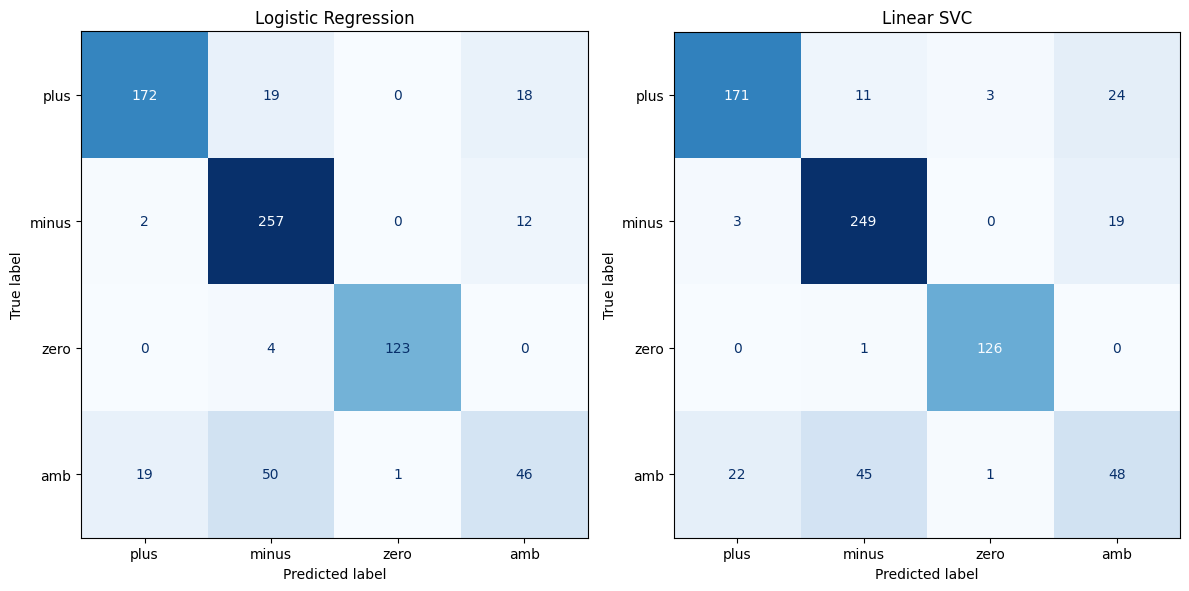

In [150]:
#TODO: ConfusionMatrix

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, title, preds in [(axes[0], "Logistic Regression", val_pred_lr), (axes[1], "Linear SVC", val_pred_svm)]:
    ConfusionMatrixDisplay.from_predictions(yva, preds, labels=CLASSES, ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{title}")
plt.tight_layout()
plt.show()


1. `amb` jest mylone tak naprawdę z kazda inna klasa, glownie z minus w przypadku obu modeli.
2. `zero` nie wpada w `minus` ani razu
3. Nie np. Jak zerio nie wpadalo w minus tak minus juz wpada w zero. Sa to pojedyncze przypadki ale sie zdarzaja.


# Zadanie 6: Interpretacja wartości

Proszę znaleźć i wskazać trzy największe wartości poza przekątną. Każdą taką wartość należy skomentować jednym zdaniem interpretacji.

Przykład formy (treść jest przykładowa, proszę opisać własne wyniki):

> Model często klasyfikuje `X` jako `Y`, co może sugerować, że ______.

Trzy największe wartości poza przekątną macierzy LogReg (**gold → pred**):

1. Najbardziej dla obu modeli rzuca się w oczy nieprawidlowe przypisanie klasy `minus` do tesktow z klasy `amb`. Mozliwe ze takie teksty moga miec slowa typowe dla negatywnych opinii, ale jednak sa `amb`.
2.  Niewiele mniej razy klasa rzeczywista `amb` rowniez wpada w modelu do `plus`. Ambigues jest to jednak niejednoznaczny tekst. Więc tak jak powyzej, moga w nim byc nie tylko negatywne slowa ale rowniez pozytywne. Jest w koncu niejednoznaczny. Model moze wyznaczyc go jako pozytywna opinia.
3.  Model rowniez myli klase `amb` w druga strone. To znaczy, ze jako `amb` wyznacza np. teksty pozytywne. Powód jak w podpunktach powyzej. 

Wniosek jest oczywisty. Klasa `amb` jest problematyczna dla obu modeli w kazda strone. I ta klase trudno jest wyznaczyc i jako tą klasę modele wyznaczają teksty które wcale do niej nie nalezą.



# Word n-grams vs character n-grams

Polski jest językiem fleksyjnym. Jakie ma to znaczenie w przetwarzaniu języka?

Porównamy teraz dwie reprezentacje:

### A. słowa
```python
analyzer="word", ngram_range=(1, 2)
```

### B. znaki
```python
analyzer="char_wb", ngram_range=(3, 5)
```

Pozostałe parametry (`min_df=2`, `sublinear_tf=True`) muszą być takie same w obu wariantach, a `max_features` podany jawnie. Proszę raportować liczbę cech. Inaczej porównujemy nie reprezentację, tylko jej rozmiar (zasada „zmieniamy jeden element").

Character n-grams potrafią częściowo radzić sobie z:

- odmianą,
- literówkami,
- wariantami słowotwórczymi,
- nieformalną pisownią.

### Hipoteza

Która reprezentacja będzie lepsza na polskich recenzjach?

Proszę sformułować hipotezę przed wykonaniem eksperymentu.

> Hipoteza: Polski jest fleksyjny (dużo odmian, literówek i nieformalnej pisowni w recenzjach), więc reprezentacja znakowa `char_wb` powinna być lepsza od czysto słownej — łapie wspólne rdzenie i warianty pisowni. Spodziewam się przewagi `char_wb` nad `word`.


In [151]:
#TODO: word_ngrams vs. char_ngrams


max_features = 50_000
representations = {
    "word (1,2)": TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=max_features, sublinear_tf=True),
    "char_wb (3,5)": TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=max_features, sublinear_tf=True),
}

rep_rows = []
for rep_name, vec in representations.items():
    row, fitted, _ = assess(rep_name, build_linsvc(vec))
    row["n_features"] = len(fitted.named_steps["tfidf"].vocabulary_)
    rep_rows.append(row)
pd.DataFrame(rep_rows)[["model", "n_features", "accuracy", "macro_f1", "macro_f1_ci95", "train_s", "infer_ms/doc"]].round(4)


,model,n_features,accuracy,macro_f1,macro_f1_ci95,train_s,infer_ms/doc
0,"word (1,2)",50000,0.8216,0.7880,"[0.758, 0.817]",1.073,0.0555
1,"char_wb (3,5)",50000,0.8285,0.7973,"[0.768, 0.824]",2.560,0.3324


Reprezentacja znakowa rzeczywiście zwraca delikatnie lepsze wyniki, jednak większym nakladem obliczeniowym i czasem trenowania modelu.


# Zadanie 7: Ablacja (Ablation study)

Proszę porównać co najmniej 4 warianty:

1. word unigram,
2. word `(1, 2)`,
3. char `(3, 5)`,
4. word `(1, 2)` z inną wartością `min_df` albo `max_features`.

Proszę użyć tego samego LinearSVC.

> UWAGA: zmieniamy jeden element pipeline'u i sprawdzamy, co rzeczywiście daje poprawę.

In [152]:
#TODO: ablation_study


ablation_variants = {
    "word (1,1)": TfidfVectorizer(analyzer="word", ngram_range=(1, 1), min_df=2, max_features=max_features, sublinear_tf=True),
    "word (1,2)": TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=max_features, sublinear_tf=True),
    "char_wb (3,5)": TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=max_features, sublinear_tf=True),
    "word (1,2), min_df=5": TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=5, max_features=max_features, sublinear_tf=True),
}
abl_rows = []
for abl_name, vec in ablation_variants.items():
    row, fitted, _ = assess(abl_name, build_linsvc(vec))
    row["n_features"] = len(fitted.named_steps["tfidf"].vocabulary_)
    abl_rows.append(row)
ablation_study = pd.DataFrame(abl_rows)[["model", "n_features", "accuracy", "macro_f1", "macro_f1_ci95"]]
ablation_study.round(4)


,model,n_features,accuracy,macro_f1,macro_f1_ci95
0,"word (1,1)",29339,0.8133,0.7819,"[0.753, 0.811]"
1,"word (1,2)",50000,0.8216,0.7880,"[0.758, 0.817]"
2,"char_wb (3,5)",50000,0.8285,0.7973,"[0.768, 0.824]"
3,"word (1,2), min_df=5",23255,0.8174,0.7861,"[0.757, 0.813]"


#### Komentarz
Najlepsza jest reprezentacja znakowa `char_wb (3,5)` - najwyzsze F1 ok. 0.797, co potwierdza hipotezę o fleksyjności polskiego. 
Zaostrzenie `min_df=5` lekko obniża wynik (F1 ok 0.786), bo wycina rzadkie, ale użyteczne cechy. 
Największą realną poprawę daje zmiana reprezentacji na znakową.



# Analiza błędów

To jest jedna z najważniejszych części laboratorium.

Żeby zrozumieć, jak i do jakich danych możemy nasz model zastosować, pytamy:

> „Jakie typy błędów popełnia model?”

Proszę zbudować DataFrame z:

- tekstem,
- gold labels,
- predykcją,
- informacją `correct`,
- długością tekstu.


In [153]:
#TODO: error_analysis


val_proba_lr = logreg_pipeline.predict_proba(Xva)
confidence_lr = val_proba_lr.max(axis=1)
error_df = pd.DataFrame({
    "text": Xva.values,
    "gold_labels": yva.values,
    "prediction": val_pred_lr,
    "correct": yva.values == val_pred_lr,
    "n_words": val_df["n_words"].values,
    "confidence": confidence_lr,
})
error_df.head()


,text,gold_labels,prediction,correct,n_words,confidence
0,"Pani Doktor bardzo miła , ale szkła dobrane mam źle - w gabinecie było ciemno ( nieodpowiednie oświetlenie gabinetu ) , a soczewki których używa okulista w gabinecie do badania...",minus,minus,True,79,0.564974
1,"Pani doktor jest rzeczowa , odpowiada na każde pytanie konkretnie , nie ogólnikami , co bardzo istotne . Spodobało mi się również podczas wizyty u Pani , jej szczera opinia i p...",plus,plus,True,116,0.441149
2,Powinno być zero albo nawet - 10 . Najgorszy lekarz u jakiego dotychczas była m . Poszła m z 3 miesięcznym niemowlakiem ze względu na kolki . Dostała m zestaw wszystkich możliw...,minus,minus,True,108,0.817997
3,Swoje osiągnięcie Mańka zaprezentował podczas trwającego od czwartku do piątku w Katowicach kongresu „ Investing in Medical Innovations ” . Opiera się ono na badaniach przeprow...,zero,zero,True,125,0.633448
4,""" To wymaga współpracy z instytutami badawczymi , wielkim przemysłem i wyszukiwania innowacyjnych pomysłów , które powstają w czasie badań naukowych , a potem wprowadzania ich ...",zero,zero,True,136,0.903265


In [154]:
display(error_df.groupby("correct")[["n_words", "confidence"]].median())

,n_words,confidence
correct,,
False,105.0,0.451675
True,123.0,0.676003



# Zadanie 8: Zacne przypadki porażek

Proszę wylosować (`random_state=RANDOM_STATE`) 10 błędnych przykładów i dodatkowo wybrać 5 błędów o najwyższej pewności modelu (maksimum z predict_proba dla LogisticRegression). Każdemu proszę ręcznie przypisać kategorię błędu. Losowanie, a nie ręczny wybór, zapewnia reprezentatywność taksonomii.

Proponowana taksonomia:

- `AMBIGUOUS_GOLD`: etykieta sama jest dyskusyjna,
- `MIXED_SENTIMENT`: tekst zawiera pozytywne i negatywne fragmenty,
- `NEGATION`: problem z negacją,
- `IRONY_SARCASM`,
- `LONG_CONTEXT`,
- `VERY_SHORT`,
- `DOMAIN_TERM`,
- `SPELLING_NOISE`,
- `NON_REVIEW`: tekst wygląda na artykuł prasowy, a nie recenzję,
- `PRETOKENIZATION`: błąd związany ze spacjowaniem interpunkcji lub odciętymi końcówkami (`miała m`, `Był em`),
- `OTHER`.

Jeśli są potrzebne, proszę dodać wasne klasy.

### Wynik

| error_type | count | przykład | obserwacja |
|---|---:|---|---|

In [155]:
# 10 losowych błędów (reprezentatywność) + 5 błędów o najwyższej pewności modelu
errors_only = error_df[~error_df["correct"]].copy()
random_errors = errors_only.sample(10, random_state=RANDOM_STATE)
confident_errors = errors_only.drop(random_errors.index).nlargest(5, "confidence")
failure_gallery = pd.concat([
    random_errors.assign(source="random"),
    confident_errors.assign(source="top_confidence"),
])

with pd.option_context("display.max_colwidth", 800):
    display(failure_gallery[["source", "gold_labels", "prediction", "confidence", "n_words", "text"]])


,source,gold_labels,prediction,confidence,n_words,text
127,random,amb,minus,0.703943,83,"Była m zadowolona z przebiegu leczenia , ale niestety rozczarowała m się na sam koniec kiedy dostała m wadliwe wkładki retencyjne ( górna wyskakiwała a dolna była zrobiona źle i nie dało się jej włożyć ) a pani nie chciała się ze mną spotkać żeby je poprawić tylko odesłała mnie do najbliższego gabinetu dentystycznego żeby mi je podpiłowali w efekcie czego dzisiaj chcą założyć mi po raz drugi aparat : ("
302,random,plus,minus,0.585614,56,"Wizyta była miła , ale nie stać mnie na tą Klinikę . Szkoda bo Pani Doktor ma mikroskop , którego szukała m dwa lata by wyciągnąć ze starego zęba leczonego kanałowo urwany kawałek metalu . Człowieka na rencie nie stać na nic i tu nie ma winy Pani Doktor . Pozdrawiam serdecznie ."
260,random,minus,plus,0.424273,286,"Do pani doktor Ewy Pawlak trafił em po przeczytaniu pozytywnych opinii na jej temat . Niestety , bardzo się rozczarował em . Konkrety . . . Pani Ewa wystawiła diagnozę jeszcze przed zapoznaniem się z dostarczonymi wynikami badań . Zaznaczę , że moje schorzenie jest bardzo poważne , a obrazy rezonansów magnetycznych niezwykle istotne . Pani doktor nie włączyła żadnej z przyniesionych płyt TK , choćby ostatniego badania . Ogólnie całą dokumentację medyczną przejrzała bardzo pobieżnie . Przynajmniej przy pierwszej wizycie pacjenta wypadało by poświęcić troszkę więcej czasu . Najwidoczniej czas to pieniądz - niektórzy zauważalnie wyznają tę zasadę . Wielokrotne spojrzenia na zegarek , wreszcie wprost wrócenie mi uwagi , że już 10min temu powinien wejść następny pacjent . Cóż , wypadało by ..."
499,random,minus,amb,0.398829,116,"Mieli śmy wątpliwa przyjemność siedzenia tam świat . Hotel a zwłaszcza obsługa zatrzymała się w czasach PRL - wystrój pełen pstrokacizny a obsługa nie dość ze niedouczona to często w przypominająca nie tylko zachowaniem ale i strojem PRL - o ile stroje to wina zarządzających - to podejście do klienta dające silnie do zrozumienia jak bardzo jest się zmęczonym ta praca jest co najmniej nie na miejscu . Jedzenie masowe , bez entuzjazmu , a za te cenę mozna oczekiwać czegoś więcej . Nie ma tez co ukrywać ze na klimat duży wpływ ma dość specyficzna klientela natomiast na to hotel nie może mieć wpływu ."
362,random,plus,amb,0.491059,81,"Hotel nowy , duże pokoje , miejsca do siedzenia i stoliki w jednym pomieszczeniu , a sypialnia w drugim ( na 1 piętrze ) . Brakowało mi miejsca na umywalce na jakieś drobiazgi , bardzo dobre kosmetyki nie wysuszające skóry . Śniadania standardowe jeśli chodzi o bufet , jednak pyszne ciasta w trzech rodzajach i aromatyczna kawa . Panie z obsługi smażą jajecznicę na bieżąco więc jest gorąca . Lokalizacja bardzo dobra , blisko do niewielkiej galerii handlowej , do rynku i do Katedry ."
559,random,amb,plus,0.396348,118,"Zdecydowała m się zarezerwować ten hotel ze względu na możliwość skorzystania z hotelowego Spa . Z recepcji otrzymała m mail - a , że wyznaczono mi wejście na godzinę 19 w dniu przyjazdu . Po zejściu o wyznaczonej godzinie do części wellness okazało się , że obsługa dopiero o tej godzinie uruchamia poszczególne obiekty term . W związku w tym , z powodu zbyt niskiej temperatury , nie mogła m skorzystać z łaźni suchej , parowej oraz z podgrzewanych leżanek . Sama strefa wellness jest mała ale dobrze wyposażona . Pokój , który zajmowała m był czysty i wygodny . Hotel jest bardzo dobrze zlokalizowany w sąsiedztwie głównych atrakcji Segowii ."
392,random,amb,plus,0.459742,113,"Duży wyremontowany częściowo Hotel nastawiony głównie na organizacje kongresów , kuchnia typowo kongresowa , w czasie gdy był em gościem hotelu , hotel miał pełne obłożenie , więc do posiłków serwowanych w jednym czasie były spore kolejki , zaplecze kongresowe oceniam na 4 , dobrze wyposażone sale miła obsługa , część hotelowa w której spał em niewyremontowana o niższym standardzie niż wyremontowana , bardzo przyjemna strefa SPA na 5 z dużym basenem i nagrzanym saunami 

Wypelniona tabelka:

| idx | gold → pred | error_type |
|---|---|---|
| 127 | amb → minus | AMBIGUOUS_GOLD |
| 302 | plus → minus | AMBIGUOUS_GOLD |
| 260 | minus → plus | LONG_CONTEXT |
| 499 | minus → amb | SPELLING_NOISE |
| 362 | plus → amb | MIXED_SENTIMENT |
| 559 | amb → plus | SPELLING_NOISE |
| 392 | amb → plus | MIXED_SENTIMENT |
| 714 | amb → minus | MIXED_SENTIMENT |
| 561 | amb → minus | AMBIGUOUS_GOLD |
| 48 | amb → plus | IRONY_SARCASM |
| 688 | amb → minus | NEGATION |
| 247 | amb → plus | MIXED_SENTIMENT |
| 428 | amb → minus | NEGATION |
| 555 | amb → minus | AMBIGUOUS_GOLD |
| 194 | amb → plus | NEGATION |


Druga tabelka:

| error_type | count | przykład (skrót) | obserwacja |
|---|---:|---|---|
| `MIXED_SENTIMENT` | 4 | "Byłam zadowolona … **ale** … dostałam wadliwe wkładki” | Tekst ma wyraźne plusy i minusy; model wybiera stronę wyrazistą, czyli zazwyczaj `minus`. |
| `AMBIGUOUS_GOLD` | 4 | "ale niestety rozczarowałam się na sam koniec” | Etykieta jest zdecydowanie źle przydzielona w oryginalnym zbiorze. |
| `SPELLING_NOISE` | 2 | "Mieli śmy wątpliwa przyjemność siedzenia tam świat " | Nie rozumiem tego zdania. Zgaduje ze model rowniez |
| `NEGATION` | 2 | "Panie z obsługi wpierw nie mogły znaleźdź rezerwacji " | Sygnał im dalej w tekst jest coraz bardziej negatywny. |
| `IRONY_SARCASM` | 1 | "Ma dużo do powiedzenia” | Model traktuje to zdanie powaznie i daje etykiete pozytywna. |
| `LONG_CONTEXT` | 1 | "Konkrety . . . Pani Ewa wystawiła diagnozę jeszcze przed zapoznaniem się " | Cala opowiesc wizyty. Z takiego tekstu jak raport ciezko wysnuc etykiete. Czlowiek tez by sie pomylil.




>Ogólna obserwacja: Najpewniejsze błędy mają `gold = amb` — model z wysoką pewnością wciska opinie niejednoznaczne w `minus`/`plus`.


# Czy długość tekstu zmienia jakość?

PProszę podzielić split walidacyjny na 4 koszyki długości według **kwartyli** `n_words` z Lab 1 (`pd.qcut(val_df["n_words"], 4, duplicates="drop")`, liczone regexem `\w+`, nie `split()`). Stałe progi (0–10, 11–30, ...) mogą dać puste koszyki, bo recenzje w tym zbiorze są długie.

Proszę policzyć accuracy i macro-F1 osobno dla każdego koszyka.

### Uwaga

Macro-F1 na bardzo małym segmencie może być niestabilne. Istotne jest zaraportowanie `n`.

In [156]:
# TODO: przypisanie koszyków i tabela: koszyk | n | accuracy | macro-F1


val_len = val_df.copy()
val_len["pred"] = val_pred_lr
val_len["length_bin"] = pd.qcut(val_len["n_words"], 4, duplicates="drop")

bucket_rows = []
for bin_label, grp in val_len.groupby("length_bin", observed=True):
    bucket_rows.append({
        "koszyk (n_words)": str(bin_label),
        "n": len(grp),
        "accuracy": accuracy_score(grp["target"], grp["pred"]),
        "macro_f1": f1_score(grp["target"], grp["pred"], labels=CLASSES, average="macro", zero_division=0),
    })
length_quality = pd.DataFrame(bucket_rows)
length_quality.round(3)


,koszyk (n_words),n,accuracy,macro_f1
0,"(33.999, 84.0]",182,0.791,0.715
1,"(84.0, 120.0]",182,0.808,0.773
2,"(120.0, 160.5]",178,0.899,0.850
3,"(160.5, 764.0]",181,0.812,0.766


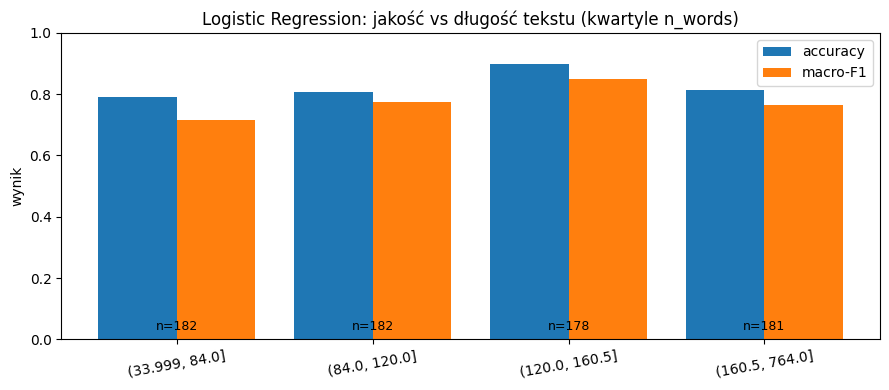

In [157]:
# TODO: wykres accuracy i macro-F1 vs koszyk (z podaniem n przy każdym słupku)


pos = np.arange(len(length_quality))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pos - 0.2, length_quality["accuracy"], width=0.4, label="accuracy")
ax.bar(pos + 0.2, length_quality["macro_f1"], width=0.4, label="macro-F1")
for p, n in zip(pos, length_quality["n"]):
    ax.text(p, 0.03, f"n={n}", ha="center", color="black", fontsize=9)
ax.set_xticks(pos)
ax.set_xticklabels(length_quality["koszyk (n_words)"], rotation=10)
ax.set_ylim(0, 1)
ax.set_ylabel("wynik")
ax.set_title("Logistic Regression: jakość vs długość tekstu (kwartyle n_words)")
ax.legend()
plt.tight_layout()
plt.show()


#### Komentarz
Roznica jest zdecydowanie widoczna. Najsłabszy jest najkrótszy kwartyl (n_words <= 84) - krótkie recenzje dają mniej sygnału. Najlepszy jest trzeci kwartyl (ok 120–160 słów). Bardzo długie teksty (ostatni kwartyl) znowu powoduja zmniejszenie wartosic obu metryk i to o sporo: ok 10 punktow procentowych dla accuracy i dla F1 wzgledem najlepszego wyniku dla trzeciegom(najlepszego) kwartylu. Zbyt dlugie teksty maja wieksze prawdopodobienstwo, ze beda mieszac slowa pozytywne z negatywnymi, bo po prostu mamy juz za duzo slow wiec tez coraz wiecej slow ze slownika.


# Czego właściwie nauczył się model?

Dla modelu liniowego możemy obejrzeć cechy o największych wagach.

To nie jest pełne wyjaśnienie modelu, ale bardzo użyteczne narzędzie diagnostyczne.

Dla każdej klasy proszę wypisać:

- 15 cech o najwyższej dodatniej wadze,
- 15 o najniższej.

Tym samym proszę sprawdzić, czy model uczy się sensownych sygnałów, czy przypadkowych artefaktów.


In [158]:
# TODO: dla LogisticRegression: pipeline.named_steps["tfidf"].get_feature_names_out() oraz clf.coef_ (kształt: klasy × cechy). Po 15 cech o najwyższej i najniższej wadze na klasę


feat_names = logreg_pipeline.named_steps["tfidf"].get_feature_names_out()
logreg_clf = logreg_pipeline.named_steps["clf"]

top_features = {}
for row_idx, cls in enumerate(logreg_clf.classes_):
    coefs = logreg_clf.coef_[row_idx]
    ranked = np.argsort(coefs)
    top_features[(cls, "+15 (za klasą)")] = feat_names[ranked[::-1][:15]]
    top_features[(cls, "-15 (przeciw)")] = feat_names[ranked[:15]]
pd.DataFrame(top_features)


amb                        minus                         plus  \
   +15 (za klasą) -15 (przeciw) +15 (za klasą) -15 (przeciw) +15 (za klasą)   
0             ale       polecam    nie polecam        zawsze        polecam   
1              ok   nie polecam            nie        bardzo         bardzo   
2        niestety      odradzam       odradzam          jest         zawsze   
3          pokoje        dzięki       niestety        czysty        doktora   
4            brak       lekarzy             po          prof           miła   
5          jednak        sposób           brak        czyste         czyste   
6           minus          proc            nic           dla        lekarzy   
7            dość           lat            sie        dzięki         jestem   
8           dobre         nigdy         brudne       smaczne         dzięki   
9       śniadania          jego          nawet         dobre       dziękuję   
10             za         także         innego       centrum   bardzo dobre   
11        ogólnie            dr        lekarza          duży        smaczne   
12          hotel         która          chyba         także     serdecznie   
13          dobra          roku         pokoju          proc       naprawdę   
14          co do   jedyny plus             bo        czysto      wszystkim   

                           zero                
   -15 (przeciw) +15 (za klasą) -15 (przeciw)  
0       niestety           proc        bardzo  
1            nie           prof           nie  
2    nie polecam         polsce       polecam  
3           brak            czy          mnie  
4       odradzam            pap        doktor  
5             bo         będzie          pani  
6            czy             są       obsługa  
7         jednak         hoteli            mi  
8             ok           roku            em  
9             za          także        pokoje  
10      nie jest           mogą           ale  
11          albo          które         hotel  
12         stare             np            po  
13            zł           oraz      niestety  
14        brudne            ich           sie


# Zadanie 9: Ewaluacja cech

Proszę znaleźć:

1. trzy cechy, które wyglądają sensownie,
2. trzy cechy, które mogą być skrótem / artefaktem (podpowiedź: proszę przejrzeć tokeny krótkie i funkcyjne oraz pozostałości po pre-tokenizacji tekstów, np. `em`, `śmy`; domyślny tokenizer odrzuca tokeny jednoznakowe, więc `m` w `miała m` zniknie, a `em` w `Był em` zostanie),
3. jedną cechę, której obecność Cię zaskoczyła.

Następnie proszę odpowiedzieć:

> Czy wysoka waga cechy oznacza związek przyczynowy?


1. `nie polecam` / `odradzam` → `minus`; `polecam` / `dziękuję` / `smaczne` / `miła` → `plus`; `ale` / `jednak` / `niestety` → `amb` (słowa kontrastu pasują do niejednoznaczności).
2. `sie` (literówka „się”) oraz krótkie słowa funkcyjne (`po`, `za`, `bo`, `czy`) z dużymi wagami; dla klasy `zero` cechy `proc`, `prof` — to sygnały domeny np encyklopedycznej, prasowej, a nie sentymentu
3. token minus jako silna cecha klasy `amb`

> Czy wysoka waga cechy oznacza związek przyczynowy?: Nie. Wagi pokazują korelację w tym konkretnym zbiorze, a nie związek przyczynowy — część cech to artefakty pre-tokenizacji i domeny, które mogą nie przenieść się na inne dane.



# Prawdopodobieństwo predykcji i selektywna klasyfikacja

`LogisticRegression` zwraca `predict_proba`.

Możemy zbudować prostą zasadę:

> jeśli maksymalne prawdopodobieństwo < próg, model nie odpowiada.

To nazywamy m.in. abstention, reject option albo selektywną klasyfikacją.

W prawdziwym wdrożonym systemie czasem lepiej powiedzieć:

> „nie wiem / skieruj do człowieka”

niż wymusić odpowiedź.


In [159]:
#TODO: predict_proba

max_proba_val = val_proba_lr.max(axis=1)
print("Rozkład pewności (max predict_proba) na validation:")
pd.Series(max_proba_val, name="max_proba").describe()


Rozkład pewności (max predict_proba) na validation:


count    723.000000
mean       0.631241
std        0.163934
min        0.273898
25%        0.474703
50%        0.633448
75%        0.771787
max        0.946087
Name: max_proba, dtype: float64


# Zadanie 10: Pokrycie i jakość

Dla progów:

`0.40, 0.50, 0.60, 0.70, 0.80, 0.90`

proszę policzyć:

- `coverage`: na jakiej części danych model udziela odpowiedzi,
- accuracy na zaakceptowanych przykładach,
- macro-F1 na zaakceptowanych przykładach.

Uwaga: przy wysokich progach niektóre klasy mogą nie wystąpić wśród zaakceptowanych przykładów. Proszę liczyć `f1_score(..., labels=CLASSES, average="macro", zero_division=0)` i raportować `n` zaakceptowanych. Prawdopodobieństwa dostępne są tylko dla LogisticRegression (LinearSVC nie ma `predict_proba`).

Proszę narysować:

`coverage` vs `accuracy`

### Pytanie

Czy da się zwiększyć jakość systemu bez zmiany modelu? Jeśli tak, to jak?

In [160]:
# TODO: coverage vs accuracy


CONF_THRESHOLDS = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
cov_rows = []
for thr in CONF_THRESHOLDS:
    keep = max_proba_val >= thr
    if keep.any():
        acc_sel = accuracy_score(yva.values[keep], val_pred_lr[keep])
        f1_sel = f1_score(yva.values[keep], val_pred_lr[keep], labels=CLASSES, average="macro", zero_division=0)
    else:
        acc_sel = f1_sel = np.nan
    cov_rows.append({"threshold": thr, "n_accepted": int(keep.sum()),
                     "coverage": keep.mean(), "accuracy": acc_sel, "macro_f1": f1_sel})
coverage_quality = pd.DataFrame(cov_rows)
display(coverage_quality.round(3))


,threshold,n_accepted,coverage,accuracy,macro_f1
0,0.4,667,0.923,0.856,0.809
1,0.5,521,0.721,0.929,0.839
2,0.6,405,0.560,0.951,0.807
3,0.7,274,0.379,0.974,0.740
4,0.8,140,0.194,1.000,0.750
5,0.9,23,0.032,1.000,0.750


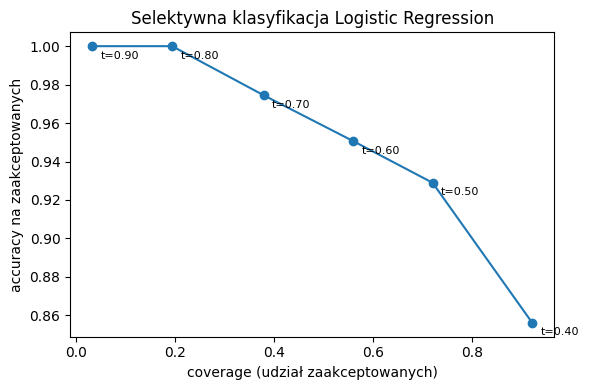

In [161]:

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(coverage_quality["coverage"], coverage_quality["accuracy"], marker="o")
for _, r in coverage_quality.iterrows():
    ax.annotate(f"t={r['threshold']:.2f}", (r["coverage"], r["accuracy"]),
                textcoords="offset points", xytext=(6, -9), fontsize=8)
ax.set_xlabel("coverage (udział zaakceptowanych)")
ax.set_ylabel("accuracy na zaakceptowanych")
ax.set_title("Selektywna klasyfikacja Logistic Regression")
plt.tight_layout()
plt.show()

#### Komentarz
Jakość systemu moznaby poprawić np. poprzez pretokenizację. np. sklejanie odciętych końcówek, usuwanie spacji w środku slowa.

In [162]:
# TODO: improvement_experiment


import re

suffix_pattern = re.compile(r"(\w) (m|em|śmy|ście|ś)\b")

def repair_pretokenization(txt):
    txt = suffix_pattern.sub(r"\1\2", txt)        # "Był em" -> "Byłem"
    txt = re.sub(r"\s+([.,!?:;)])", r"\1", txt)    # spacja przed interpunkcją
    txt = re.sub(r"([(])\s+", r"\1", txt)          # spacja po nawiasie
    return txt

print("przykład:", repair_pretokenization("Był em tam . Miała m wątpliwości ( naprawdę ) !"))

improvement_rows = []
for variant_name, mapper in [("surowy tekst", lambda s: s),
                             ("naprawiona tokenizacja", lambda s: s.map(repair_pretokenization))]:
    for clf_name, estimator in [("LogisticRegression", build_logreg()), ("LinearSVC", build_linsvc())]:
        row, _, _ = assess(f"{clf_name} | {variant_name}", estimator,
                           X_fit=mapper(Xtr), X_eval=mapper(Xva))
        improvement_rows.append(row)
improvement_experiment = pd.DataFrame(improvement_rows)[["model", "accuracy", "macro_f1", "macro_f1_ci95"]]
improvement_experiment.round(4)


przykład: Byłem tam. Miałam wątpliwości (naprawdę)!


,model,accuracy,macro_f1,macro_f1_ci95
0,LogisticRegression | surowy tekst,0.8271,0.7926,"[0.764, 0.823]"
1,LinearSVC | surowy tekst,0.8216,0.7880,"[0.758, 0.817]"
2,LogisticRegression | naprawiona tokenizacja,0.8354,0.8000,"[0.771, 0.829]"
3,LinearSVC | naprawiona tokenizacja,0.8216,0.7866,"[0.758, 0.816]"


#### Komentarz
Jak widzimy, jest poprawa wyników juz na jednym przykladzie przy poprawionej tokenizacji. A nie musielismy zmieniac modelu.


# Tuning hiperparametrów

Sprawdzimy jeden parametr Logistic Regression:

`C ∈ {0.1, 0.5, 1, 2, 5}`

Obliczeń dokonujemy na splicie walidacyjnym. To wystarczy, by przećwiczyć prawidłowy protokół:

`train → validation → wybór → test`


## Zadanie 11: Strojenie hiperparametru C

Proszę przeprowadzić strojenie hiperparametru C dla modelu regresji logistycznej.
- przetestować wartości C: 0.1, 0.5, 1.0, 2.0 i 5.0.
- dla każdej wartości wytrenować osobny model LogisticRegression na reprezentacji TF-IDF zbioru treningowego.
- wykonać predykcję dla zbioru walidacyjnego.
- obliczyć metryki jakości modelu, w szczególności macro F1.
- zapisać wyniki dla wszystkich wartości C w tabeli.
- posortować wyniki malejąco według macro F1.
- wybrać wartość C, dla której model uzyskał najlepszy wynik na zbiorze walidacyjnym.
Jeśli najlepsze C leży na brzegu siatki (5.0), proszę poszerzyć siatkę i powtórzyć.

Na końcu krótko odpowiedzieć: jak zmiana wartości C wpłynęła na jakość klasyfikacji i która wartość została wybrana?

In [163]:
# TODO: strojenie C na validation (nie na test!)


def sweep_C(values):
    out = []
    for C in values:
        row, _, _ = assess(f"C={C}", build_logreg(C=C))
        row["C"] = C
        out.append(row)
    return pd.DataFrame(out)

C_values = [0.1, 0.5, 1.0, 2.0, 5.0]
tuning_table = sweep_C(C_values)

if tuning_table.loc[tuning_table["macro_f1"].idxmax(), "C"] == max(C_values):
    tuning_table = pd.concat([tuning_table, sweep_C([10.0, 20.0, 50.0, 100.0])], ignore_index=True)

tuning_table = tuning_table.sort_values("macro_f1", ascending=False).reset_index(drop=True)
tuning_table[["C", "accuracy", "macro_f1", "macro_f1_ci95", "macro_precision", "macro_recall", "train_s"]].round(4)


,C,accuracy,macro_f1,macro_f1_ci95,macro_precision,macro_recall,train_s
0,5.0,0.8243,0.7967,"[0.767, 0.824]",0.8078,0.7907,1.738
1,2.0,0.8257,0.7954,"[0.767, 0.823]",0.8093,0.7888,1.697
2,1.0,0.8271,0.7926,"[0.764, 0.823]",0.8168,0.7841,1.440
3,20.0,0.8160,0.7901,"[0.760, 0.818]",0.7969,0.7859,1.900
4,100.0,0.8147,0.7881,"[0.759, 0.816]",0.7920,0.7860,1.931
5,50.0,0.8133,0.7877,"[0.759, 0.815]",0.7908,0.7860,1.750
6,10.0,0.8160,0.7871,"[0.759, 0.815]",0.7953,0.7825,1.673
7,0.5,0.8174,0.7656,"[0.735, 0.796]",0.8112,0.7595,1.341
8,0.1,0.6833,0.5705,"[0.543, 0.594]",0.6089,0.5847,1.112


In [164]:
BEST_C = float(tuning_table.loc[0, "C"])
print("Wybrane C (na validation):", BEST_C)

Wybrane C (na validation): 5.0


#### Komentarz
Zbyt mocna regularyzacja (C = 0.1) wyraźnie szkodzi. Zwiększanie C poprawia wynik aż do nasycenia: C = 1 wtedy wynik F1 to ok. 0.79. Dalej wartość F1 poprawia się delikatnie wraz ze wzrostem C. Mimo wszystko wybralabym C = 5 bo dla niego dostajemy największą wartość metryki F1 na ktorej najbardziej nam zalezy.



# Zadanie 12: Finalista

Na podstawie splitu proszę wybrać jeden finalny pipeline.

Nie musi to być model z absolutnie najwyższym wynikiem, jeśli różnica jest minimalna, a koszt znacząco większy.

Proszę uzasadnić:

> **Wybrany model:** ...

> **Dlaczego:** ...

> **Najważniejszy trade-off:** ...


#### Wybrany model
TF-IDF(char_wb 3,5) + LinearSVC.

#### Dlaczego
Spośród badanych reprezentacji to `char_wb (3,5)` dawała najwyższe macro-F1 na walidacji (≈ 0.797, na remis z word + LogReg C=5 ≈ 0.797 i lepiej niż word + SVM ≈ 0.788 — różnice mieszczą się w przedziale ufności, więc jakościowo jest to remis). Kluczowy argument to **odporność**: w teście robustness (Zadanie 14D) reprezentacja znakowa była zdecydowanie najmniej wrażliwa na zaszumienie danych (usunięcie polskich znaków, literówki), podczas gdy model słowny mocno tracił. Dla polskiego (fleksja, literówki, nieformalna pisownia) char n-gramy łapią wspólne rdzenie i warianty pisowni, więc lepiej generalizują na „brudne” teksty.

#### Najważniejszy trade-off
Wybieram odporność i (minimalnie) wyższą jakość kosztem większego i wolniejszego modelu (char_wb ma znacznie więcej n-gramów → dłuższy trening i inferencja) oraz braku `predict_proba` w `LinearSVC` — selektywną klasyfikację trzeba by oprzeć o `decision_function` (margines) lub kalibrację, zamiast gotowych prawdopodobieństw jak w LogisticRegression.



# Zadanie 13: Ostateczny test modelu

Kiedy mamy już wszystkie niezbędne informacje, wolno nam użyć test setu do finalnej oceny.

Proszę wybrać konfigurację na podstawie validation i:

1. połącz `train + validation`,
2. wytrenuj model od nowa,
3. oceń dokładnie raz na `test`.

Proszę nie poprawiać konfiguracji po zobaczeniu testu ;)


In [165]:
#TODO: TEST


FINAL_DESC = "TF-IDF(char_wb 3,5) + LinearSVC"
final_pipe = build_linsvc(representations["char_wb (3,5)"])

X_trainval = pd.concat([Xtr, Xva], ignore_index=True)
y_trainval = pd.concat([ytr, yva], ignore_index=True)

start = time.perf_counter()
final_pipe.fit(X_trainval, y_trainval)
final_train_s = time.perf_counter() - start

# oceniamy DOKŁADNIE raz na test
test_pred = final_pipe.predict(Xte)
test_point, test_lo, test_hi = bootstrap_ci(yte, test_pred, macro_f1)
final_test_result = {
    "model": FINAL_DESC,
    "test_accuracy": accuracy_score(yte, test_pred),
    "test_macro_f1": test_point,
    "test_macro_f1_ci95": f"[{test_lo:.3f}, {test_hi:.3f}]",
    "train_s": round(final_train_s, 3),
}
print(classification_report(yte, test_pred, labels=CLASSES, digits=3))
final_test_result


              precision    recall  f1-score   support

        plus      0.826     0.843     0.834       197
       minus      0.840     0.877     0.858       300
        zero      0.991     0.940     0.965       117
         amb      0.557     0.500     0.527       108

    accuracy                          0.821       722
   macro avg      0.803     0.790     0.796       722
weighted avg      0.818     0.821     0.819       722



{'model': 'TF-IDF(char_wb 3,5) + LinearSVC',
 'test_accuracy': 0.8213296398891967,
 'test_macro_f1': 0.795996861012207,
 'test_macro_f1_ci95': '[0.766, 0.826]',
 'train_s': 3.038}


# NLP Arena #1

Teraz model musi zostać oceniony jak system, a nie tylko liczba F1.

Dla finalistów raportujemy:

### Quality
- macro-F1,
- accuracy.

### Speed
- czas treningu,
- inference ms / dokument.

### Size
- rozmiar zapisanego pipeline'u.

### Robustness
- wynik na krótkich tekstach,
- wynik na długich tekstach.

### Interpretability
- czy możemy obejrzeć ważne cechy?

## Kategorie

**Best Quality**: najwyższe macro-F1  
**Speed Demon**: najniższe inference time  
**Tiny but Mighty**: najlepszy stosunek jakości do rozmiaru  
**Occam Award**: najprostszy system blisko najlepszego wyniku  
**Failure Analyst**: najlepsza analiza błędów


Proszę zapisać wytrenowany model do pliku i zmierzyć podstawowe parametry związane z jego wykorzystaniem.
- zapisać końcowy model do pliku w formacie joblib.
- obliczyć rozmiar zapisanego modelu w MB.
- wyświetlić czas treningu modelu w sekundach.
- obliczyć średni czas inferencji dla jednego dokumentu i podać go w milisekundach na dokument (ms/doc).
- zapisać otrzymane wartości i wykorzystać je później do porównania z innymi modelami.

Porównując modele, proszę zwrócić uwagę nie tylko na jakość klasyfikacji, ale również na ich rozmiar oraz koszt treningu i inferencji.

In [166]:
import tempfile

def joblib_size_mb(estimator, tag):
    with tempfile.TemporaryDirectory() as tmp:
        p = Path(tmp) / f"{tag}.joblib"
        joblib.dump(estimator, p)
        return p.stat().st_size / 1e6

FINAL_MODEL_PATH = ARTIFACTS / "baseline_final_model.joblib"
joblib.dump(final_pipe, FINAL_MODEL_PATH)
final_model_stats = {
    "model": FINAL_DESC,
    "path": str(FINAL_MODEL_PATH),
    "size_mb": round(FINAL_MODEL_PATH.stat().st_size / 1e6, 3),
    "train_s": round(final_train_s, 3),
    "infer_ms/doc": round(get_infer_s_per_doc(final_pipe, Xte), 4),
    **{k: final_test_result[k] for k in ["test_accuracy", "test_macro_f1", "test_macro_f1_ci95"]},
}
(ARTIFACTS / "baseline_final_model_metrics.json").write_text(json.dumps(final_model_stats, indent=2, ensure_ascii=False))
print(json.dumps(final_model_stats, indent=2, ensure_ascii=False))

q1_len = val_df["n_words"].quantile(0.25)
q3_len = val_df["n_words"].quantile(0.75)
short_idx = (val_df["n_words"] <= q1_len).values
long_idx = (val_df["n_words"] >= q3_len).values

arena_specs = {
    "majority": (DummyClassifier(strategy="most_frequent"), "nie dotyczy"),
    "word LogisticRegression": (build_logreg(C=BEST_C), "tak - wagi n-gramów słów"),
    "word LinearSVC": (build_linsvc(), "tak - wagi n-gramów słów"),
    "char LinearSVC": (build_linsvc(representations["char_wb (3,5)"]), "częściowo - fragmenty słów"),
}
arena_rows = []
arena_fitted = {}
for a_name, (estimator, interp) in arena_specs.items():
    row, fitted, pred = assess(a_name, estimator)
    arena_fitted[a_name] = fitted
    arena_rows.append({
        "model": a_name,
        "macro_f1": row["macro_f1"],
        "accuracy": row["accuracy"],
        "train_s": row["train_s"],
        "infer_ms/doc": row["infer_ms/doc"],
        "size_mb": round(joblib_size_mb(fitted, a_name.replace(" ", "_")), 3),
        "f1_short(Q1)": f1_score(yva.values[short_idx], pred[short_idx], labels=CLASSES, average="macro", zero_division=0),
        "f1_long(Q4)": f1_score(yva.values[long_idx], pred[long_idx], labels=CLASSES, average="macro", zero_division=0),
        "interpretable": interp,
    })


{
  "model": "TF-IDF(char_wb 3,5) + LinearSVC",
  "path": "artifacts/baseline_final_model.joblib",
  "size_mb": 3.337,
  "train_s": 3.038,
  "infer_ms/doc": 0.3318,
  "test_accuracy": 0.8213296398891967,
  "test_macro_f1": 0.795996861012207,
  "test_macro_f1_ci95": "[0.766, 0.826]"
}


In [167]:
arena = pd.DataFrame(arena_rows)
arena["f1_per_mb"] = arena["macro_f1"] / arena["size_mb"]
arena.sort_values("macro_f1", ascending=False).round(4)

,model,macro_f1,accuracy,train_s,infer_ms/doc,size_mb,f1_short(Q1),f1_long(Q4),interpretable,f1_per_mb
3,char LinearSVC,0.7973,0.8285,3.284,0.3602,3.337,0.8008,0.7883,częściowo - fragmenty słów,0.2389
1,word LogisticRegression,0.7967,0.8243,1.887,0.0683,3.633,0.7086,0.7660,tak - wagi n-gramów słów,0.2193
2,word LinearSVC,0.7880,0.8216,1.098,0.0765,3.633,0.6521,0.7498,tak - wagi n-gramów słów,0.2169
0,majority,0.1363,0.3748,0.002,0.0000,0.001,0.1417,0.1648,nie dotyczy,136.3179


#### Kategorie NLP Areny (na podstawie tabeli powyżej):
- **Best Quality:** najwyższe macro-F1 — char LinearSVC (≈ 0.797)
- **Speed Demon:** wśród sensownych modeli najkrótszy `infer_ms/doc` ma word LogReg/LinearSVC (char ma więcej cech → wolniej).
- **Tiny but Mighty:** najlepszy `f1_per_mb` — word LinearSVC.
- **Occam Award:** word LogReg (C = 5) — prosty i blisko najlepszego wyniku.
- **Failure Analyst:** analiza z Zadania 8 (dominuje mylenie `amb` → `minus`/`plus`, często z wysoką pewnością).

Kolumna `f1_long(Q4)` potwierdza, że najdluzsze teksty są najtrudniejsze dla wszystkich modeli.


# Zadanie 14: Baseline Boss Fight

Zadanie związane z areną, skupiamy się w nim na następujących aspektach:

### A. Word + char features
Proszę połączyć reprezentację słowną i znakową przez `FeatureUnion`.

### B. Class weights
Sprawdzić `class_weight="balanced"`. Czy macro-F1 rośnie? Które klasy zyskują, a które tracą?

### C. Learning curve
Proszzę wytrenować ten sam model na:

- 10% train,
- 25%,
- 50%,
- 75%,
- 100%.

Proszę powtórzyć dla 3 różnych seedów losowania podzbiorów i raportować średnią ± odchylenie.

Proszę narysować:

`liczba przykładów → macro-F1`

Proszę odpowiedzieć: Czy bardziej opłaca się zmienić model, czy zdobyć więcej danych?

### D. Robustness test
Proszę zastosować zaburzenia do całego zbioru validation (n=723; 100 przykładów daje zbyt szeroki przedział ufności). Proszę wprowadzić kontrolowany szum:

- usunąć polskie znaki,
- dodać literówki,
- zmienić wielkość liter.

Proszę sprawdzić spadek wyniku word-TF-IDF i char-TF-IDF.

### E. Cost-aware model selection
Proszę zdefiniować własny score:

```text
utility = macro_f1 - λ * log10(model_size_mb + 1)
```
Proszę sprawdzić λ ∈ {0.01, 0.05, 0.1} i sprawdzić, czy najlepszy model nadal wygrywa.

### A. Word + char features (`FeatureUnion`)

In [168]:
word_char_union = FeatureUnion([
    ("word", clone(representations["word (1,2)"])),
    ("char", clone(representations["char_wb (3,5)"])),
])
bossA_rows = []
for name, estimator in [
    ("word LinearSVC", build_linsvc()),
    ("char LinearSVC", build_linsvc(representations["char_wb (3,5)"])),
    ("word+char LinearSVC", build_linsvc(word_char_union)),
    ("word+char LogisticRegression", build_logreg(C=BEST_C, vectorizer=word_char_union)),
]:
    row, fitted, _ = assess(name, estimator)
    row["size_mb"] = round(joblib_size_mb(fitted, name.replace(" ", "_").replace("+", "_")), 3)
    arena_fitted[name] = fitted
    bossA_rows.append(row)
boss_word_char = pd.DataFrame(bossA_rows)[["model", "accuracy", "macro_f1", "macro_f1_ci95", "train_s", "infer_ms/doc", "size_mb"]]
boss_word_char.round(4)


,model,accuracy,macro_f1,macro_f1_ci95,train_s,infer_ms/doc,size_mb
0,word LinearSVC,0.8216,0.7880,"[0.758, 0.817]",1.171,0.0582,3.633
1,char LinearSVC,0.8285,0.7973,"[0.768, 0.824]",2.699,0.3485,3.337
2,word+char LinearSVC,0.8354,0.8074,"[0.781, 0.836]",3.867,0.4414,6.968
3,word+char LogisticRegression,0.8285,0.8015,"[0.772, 0.830]",6.895,0.3881,6.968


**A.** Połączenie word + char (`FeatureUnion`) daje najlepszy wynik na validation (SVM ≈ 0.807 vs 0.788 dla samego word i 0.797 dla samego char; word+char LogReg ≈ 0.802). Zysk jest realny, ale kosztem większego modelu i wolniejszej inferencji — char wnosi tu więcej niż word (fleksja), a unia łapie oba typy sygnału.


### B. Class weights (`class_weight="balanced"`)

In [169]:
bossB_rows = []
per_class_f1 = {}
for name, estimator in [
    ("LogisticRegression", build_logreg(C=BEST_C)),
    ("LogisticRegression balanced", build_logreg(C=BEST_C, class_weight="balanced")),
    ("LinearSVC", build_linsvc()),
    ("LinearSVC balanced", build_linsvc(class_weight="balanced")),
]:
    row, _, pred = assess(name, estimator)
    bossB_rows.append(row)
    per_class_f1[name] = f1_score(yva, pred, labels=CLASSES, average=None)
display(pd.DataFrame(bossB_rows)[["model", "accuracy", "macro_f1", "macro_f1_ci95"]].round(4))
pd.DataFrame(per_class_f1, index=CLASSES).T.round(3)


,model,accuracy,macro_f1,macro_f1_ci95
0,LogisticRegression,0.8243,0.7967,"[0.767, 0.824]"
1,LogisticRegression balanced,0.8188,0.8028,"[0.774, 0.830]"
2,LinearSVC,0.8216,0.7880,"[0.758, 0.817]"
3,LinearSVC balanced,0.8202,0.7928,"[0.763, 0.820]"


,plus,minus,zero,amb
LogisticRegression,0.841,0.864,0.976,0.505
LogisticRegression balanced,0.824,0.864,0.981,0.543
LinearSVC,0.844,0.863,0.981,0.464
LinearSVC balanced,0.831,0.870,0.977,0.493


**B.** `class_weight="balanced"` lekko podnosi macro-F1 (LogReg ≈ 0.797 → 0.803, SVM ≈ 0.788 → 0.793). Zyskuje przede wszystkim najsłabsza klasa `amb` (F1 ≈ 0.505 → 0.543), kosztem minimalnego spadku na `plus`. To oczekiwane: ważenie klas przesuwa uwagę modelu na rzadkie klasy, co pomaga metryce makro.


### C. Learning curve

In [170]:
fractions = [0.10, 0.25, 0.50, 0.75, 1.00]
seeds = [0, 1, 2]
curve_rows = []
for frac in fractions:
    for seed in seeds:
        subset = train_df.sample(frac=frac, random_state=seed)
        m = build_logreg(C=BEST_C).fit(subset["text"], subset["target"])
        curve_rows.append({"fraction": frac, "n_train": len(subset), "seed": seed,
                           "macro_f1": macro_f1(yva, m.predict(Xva))})
curve_df = pd.DataFrame(curve_rows)
learning_curve = curve_df.groupby(["fraction", "n_train"])["macro_f1"].agg(["mean", "std"]).reset_index()
display(learning_curve.round(4))


,fraction,n_train,mean,std
0,0.10,578,0.7038,0.0177
1,0.25,1446,0.7581,0.0018
2,0.50,2892,0.7868,0.0109
3,0.75,4337,0.7948,0.0079
4,1.00,5783,0.7967,0.0000


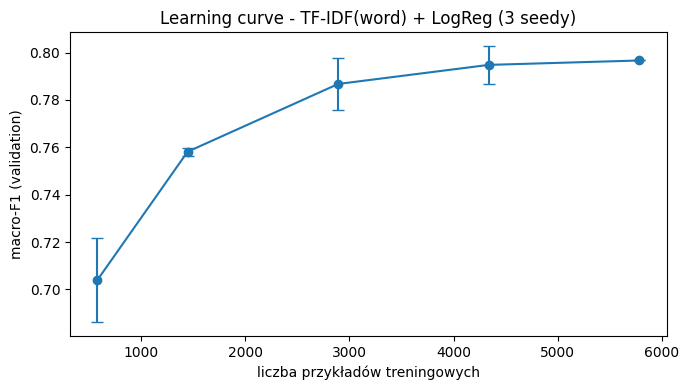

In [171]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(learning_curve["n_train"], learning_curve["mean"],
            yerr=learning_curve["std"].fillna(0), marker="o", capsize=4)
ax.set_xlabel("liczba przykładów treningowych")
ax.set_ylabel("macro-F1 (validation)")
ax.set_title("Learning curve - TF-IDF(word) + LogReg (3 seedy)")
plt.tight_layout()
plt.show()

**C. Czy więcej danych, czy inny model?** Krzywa szybko się wypłaszcza: z 10% (≈ 0.704) do 50% danych (≈ 0.787) zysk to ~+0.08, ale z 50% do 100% już tylko ~+0.01 (odchylenia między seedami ≤ 0.015). Wniosek: na tym etapie **więcej danych tego samego typu da niewiele** — bardziej opłaca się zmiana reprezentacji/modelu (char n-gramy, word+char, docelowo transformer) niż zbieranie kolejnych recenzji.


### D. Robustness test

In [172]:
polish_table = str.maketrans("ąćęłńóśźżĄĆĘŁŃÓŚŹŻ", "acelnoszzACELNOSZZ")

def strip_diacritics(txt):
    return txt.translate(polish_table)

def inject_typos(txt, rate=0.10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    toks = txt.split(" ")
    for k, w in enumerate(toks):
        if len(w) > 3 and rng.random() < rate:
            i = int(rng.integers(0, len(w) - 1))
            toks[k] = w[:i] + w[i + 1:]  # usunięcie znaku = literówka
    return " ".join(toks)

perturbations = {
    "clean": lambda s: s,
    "bez pl znaków": lambda s: s.map(strip_diacritics),
    "literówki 10%": lambda s: pd.Series([inject_typos(t, seed=i) for i, t in enumerate(s)], index=s.index),
    "losowa wielkość (UPPER)": lambda s: s.str.upper(),
}
# zaburzenia stosujemy do CAŁEGO validation (n=723)
robust_targets = {n: arena_fitted[n] for n in ["word LogisticRegression", "char LinearSVC", "word+char LinearSVC"]}
robust_rows = []
for p_name, fn in perturbations.items():
    Xp = fn(Xva)
    for m_name, model in robust_targets.items():
        robust_rows.append({"perturbacja": p_name, "model": m_name, "macro_f1": macro_f1(yva, model.predict(Xp))})
robustness = pd.DataFrame(robust_rows).pivot(index="perturbacja", columns="model", values="macro_f1").loc[list(perturbations)]
display(robustness.round(4))
print("Spadek względem 'clean':")
(robustness - robustness.loc["clean"]).round(4)


model,char LinearSVC,word LogisticRegression,word+char LinearSVC
perturbacja,,,
clean,0.7973,0.7967,0.8074
bez pl znaków,0.7875,0.7255,0.7840
literówki 10%,0.7991,0.7951,0.7980
losowa wielkość (UPPER),0.7973,0.7967,0.8074


Spadek względem 'clean':


model,char LinearSVC,word LogisticRegression,word+char LinearSVC
perturbacja,,,
clean,0.0000,0.0000,0.0000
bez pl znaków,-0.0098,-0.0711,-0.0234
literówki 10%,0.0018,-0.0016,-0.0094
losowa wielkość (UPPER),0.0000,0.0000,0.0000


**D.** Zdecydowanie najmocniej szkodzi **usunięcie polskich znaków** i uderza ono głównie w model **słowny**. Reprezentacja **znakowa** `char_wb` jest tu dużo odporniejsza. Literówki na poziomie 10% słów mają w tym zbiorze znikomy wpływ (recenzje są długie, więc większość cech przetrwa), a losowa zmiana na UPPERCASE nic nie zmienia, bo TF-IDF domyślnie sprowadza tekst do małych liter. Wniosek: przy „brudnych” danych (zwłaszcza bez diakrytyków) bezpieczniejsza jest reprezentacja znakowa lub word+char.


### E. Cost-aware model selection

In [173]:
cost_candidates = pd.concat([
    arena[["model", "macro_f1", "size_mb"]],
    boss_word_char[["model", "macro_f1", "size_mb"]],
], ignore_index=True).drop_duplicates("model").reset_index(drop=True)

for lam in [0.01, 0.05, 0.1]:
    cost_candidates[f"utility(λ={lam})"] = cost_candidates["macro_f1"] - lam * np.log10(cost_candidates["size_mb"] + 1)
display(cost_candidates.sort_values("macro_f1", ascending=False).round(4))
utility_winners = {c: cost_candidates.loc[cost_candidates[c].idxmax(), "model"]
                   for c in cost_candidates.columns if c.startswith("utility")}
print("Zwycięzca wg utility dla kolejnych λ:", utility_winners)


,model,macro_f1,size_mb,utility(λ=0.01),utility(λ=0.05),utility(λ=0.1)
4,word+char LinearSVC,0.8074,6.968,0.7984,0.7623,0.7173
5,word+char LogisticRegression,0.8015,6.968,0.7925,0.7565,0.7114
3,char LinearSVC,0.7973,3.337,0.7909,0.7654,0.7336
1,word LogisticRegression,0.7967,3.633,0.7900,0.7634,0.7301
2,word LinearSVC,0.7880,3.633,0.7813,0.7547,0.7214
0,majority,0.1363,0.001,0.1363,0.1363,0.1363


Zwycięzca wg utility dla kolejnych λ: {'utility(λ=0.01)': 'word+char LinearSVC', 'utility(λ=0.05)': 'char LinearSVC', 'utility(λ=0.1)': 'char LinearSVC'}


**E.** Przy małej karze za rozmiar (λ = 0.01) nadal wygrywa najlepszy jakościowo word+char LinearSVC. Gdy λ rośnie (0.05, 0.1), kara za rozmiar zaczyna promować mniejsze modele i na czoło wychodzi char LinearSVC (prawie tak dobry jakościowo jak word+char, ale ~2× mniejszy). Im bardziej cenimy mały model, tym bardziej opłaca się char LinearSVC mimo ~0.01 niższego macro-F1 niż word+char.



# Zadanie 15: Karta modelu

Proszę utworzyć:

```text
artifacts/baseline_model_card.md
```

Minimalna zawartość:
- Jaki pipeline?
- Co przewiduje?
- Na czym został wytrenowany?
- Jakie splity i jaka główna metryka?
- Validation i final test.
- Czas treningu i inference.
- Co wynika z zaobserwowanych porażek?
- Czy próg confidence ma sens?
- Do czego model może być użyty? Do czego nie powinien być używany?


In [174]:
# zapis karty modelu do pliku artifacts/baseline_model_card.md
char_val_macro_f1 = float(arena.loc[arena["model"] == "char LinearSVC", "macro_f1"].iloc[0])

card_text = f"""# Baseline Model Card - PolEmo 2.0 (Lab 2)

## Pipeline
{FINAL_DESC}. Reprezentacja: TF-IDF na znakach (char_wb), n-gramy (3,5), min_df=2, max_features=50k, sublinear_tf=True. Klasyfikator: LinearSVC (random_state=RANDOM_STATE).

## Co przewiduje
Sentyment polskiej recenzji konsumenckiej - jedną z 4 klas: {CLASSES}.

## Na czym wytrenowany
Artefakt z Lab 1 (`artifacts/polemo2_clean.parquet`), oficjalny podział PolEmo 2.0 / KLEJ. Finalny model trenowany na train + validation, oceniany raz na test.

## Splity i metryka główna
train (fit) / validation (wybór reprezentacji i wariantu modelu) / test (jedna końcowa ocena). Metryka główna: macro-F1 (klasy niezbalansowane, dominuje `minus`).

## Wyniki
- validation (char_wb 3,5 + LinearSVC): macro-F1 ~ {char_val_macro_f1:.3f}
- test (train+val -> test): accuracy = {final_test_result['test_accuracy']:.3f}, macro-F1 = {final_test_result['test_macro_f1']:.3f} {final_test_result['test_macro_f1_ci95']}

## Czas i rozmiar
- czas treningu finalnego: {final_model_stats['train_s']} s
- inferencja: {final_model_stats['infer_ms/doc']} ms/dokument
- rozmiar modelu: {final_model_stats['size_mb']} MB

## Dlaczego char_wb
Reprezentacja znakowa była najbardziej odporna na zaszumienie (Zadanie 14D): najmniejszy spadek macro-F1 przy usunięciu polskich znaków i literówkach, podczas gdy model słowny mocno tracił. Jakość na walidacji jest przy tym na remis z najlepszym modelem słownym (w granicach CI).

## Wnioski z porażek
Najtrudniejsza klasa to `amb` (najniższy recall/F1). Najczęstszy błąd: `amb` mylone z `minus`/`plus`, zwykle z wysoką pewnością. Z ręcznej taksonomii (Zadanie 8) główne przyczyny to: błędnie przydzielona etykieta w zbiorze (AMBIGUOUS_GOLD), mieszany wydźwięk (MIXED_SENTIMENT), negacja (NEGATION), zaszumiona pisownia (SPELLING_NOISE), ironia (IRONY_SARCASM) oraz długi kontekst (LONG_CONTEXT).

## Próg confidence
`LinearSVC` nie udostępnia `predict_proba`, więc dla finalnego modelu progowanie pewności trzeba oprzeć o `decision_function` (margines) lub kalibrację (np. `CalibratedClassifierCV`). Samą ideę selektywnej klasyfikacji pokazaliśmy w Zadaniu 10 na LogisticRegression: przy progu 0.5 model odpowiadał na ~72% przykładów z accuracy ~0.93; mechanizm ma sens, ale dla char-SVM wymaga dodatkowego kroku.

## Zastosowania
- MOŻE: wstępna priorytetyzacja/segregacja recenzji usług (lekarze, hotele), mocny i odporny baseline do porównań z większymi modelami.
- NIE POWINIEN: decyzje wysokiej stawki bez kontroli człowieka, teksty spoza domeny recenzji (poezja, polityka, social media), język inny niż polski.
"""
card_path = ARTIFACTS / "baseline_model_card.md"
card_path.write_text(card_text, encoding="utf-8")
print("Zapisano:", card_path)


Zapisano: artifacts/baseline_model_card.md



# Raport końcowy

Proszę podsumować pracę i określić:

1. **Najlepszy model:** ...
2. **Poprawa względem majority baseline:** ...
3. **Najtrudniejsza klasa:** ...
4. **Najważniejszy typ błędu:** ...
5. **Najważniejszy trade-off jakość/koszt:** ...
6. **Czy na tym etapie potrzebujemy większego modelu?** ...

Każde sformułowanie proszę uzasadnić.

1. **Najlepszy / finalny model:** finalistą jest **TF-IDF(char_wb 3,5) + LinearSVC**. Na walidacji ma najwyższe macro-F1 spośród reprezentacji (≈ 0.797, na remis z word + LogReg w granicach CI), a przede wszystkim jest **najbardziej odporny na zaszumienie** (Zadanie 14D: najmniejszy spadek przy usunięciu polskich znaków i literówkach — kluczowe dla „brudnych” danych). Na teście: accuracy ≈ **0.821**, macro-F1 ≈ **0.796** (praktycznie na równi z word + LogReg ≈ 0.802, różnica w granicach przedziału ufności).
2. **Poprawa względem majority baseline:** z macro-F1 ≈ 0.136 (majority) do ≈ 0.80 na teście — ~**+0.66** bezwzględnie; baseline pobity zdecydowanie, daleko poza przedziałem ufności.
3. **Najtrudniejsza klasa:** `amb` (F1 ≈ 0.48–0.53) — niejednoznaczna z definicji, bez własnego słownika, nakłada się na pozostałe klasy.
4. **Najważniejszy typ błędu:** mylenie `amb` → `minus`/`plus`; opinie mieszane trafiają do klas wyrazistych, zwłaszcza dominującej `minus`.
5. **Najważniejszy trade-off jakość/koszt:** wybieram **odporność** reprezentacji znakowej kosztem większego i wolniejszego modelu oraz braku `predict_proba` (w `LinearSVC` progowanie pewności wymaga `decision_function`/kalibracji). Jakość zostaje na poziomie najlepszych modeli, a zyskujemy stabilność na zaszumionych danych.
6. **Czy potrzebujemy większego modelu?** Jeszcze nie w pełni — mocny baseline osiąga ~0.80 macro-F1. Ale sufit na klasie `amb` i mieszanym sentymencie sugeruje, że model rozumiejący kontekst i negację (transformer) mógłby pomóc właśnie tam. To wydaje się naturalny kierunek.



# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli zawiera:

- [ ] majority baseline (oba warianty `DummyClassifier`);
- [ ] TF-IDF i opis macierzy rzadkiej;
- [ ] Logistic Regression;
- [ ] Linear SVM;
- [ ] leaderboard na validation z przedziałami ufności;
- [ ] classification report;
- [ ] confusion matrix;
- [ ] ablację word vs char n-grams;
- [ ] Failure Gallery z ręczną taksonomią błędów;
- [ ] analizę jakości względem długości tekstu;
- [ ] porównanie wag modelu liniowego;
- [ ] coverage vs quality;
- [ ] strojenie C (tabela, wybór na validation);
- [ ] wybór finalisty bez używania test setu;
- [ ] ostateczny test: train + validation, dokładnie jeden raz na test;
- [ ] zapisany model `.joblib` i pomiary (rozmiar, czas treningu, ms/doc);
- [ ] NLP Arena #1;
- [ ] Baseline Boss Fight;
- [ ] `baseline_model_card.md`;
- [ ] wnioski końcowe.